In [3]:
import re
import sys
from pathlib import Path

import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
REPO_ROOT = str(Path.cwd().parent.parent)
sys.path.insert(0, f"{REPO_ROOT}/src")

from photogranulo.utils.paths import load_paths

In [4]:
paths = load_paths()
SOIL_DIR = paths["raw"] / "frdr" / "images_soil"
CALIB_DIR = paths["raw"] / "frdr" / "images_calibration"

assert SOIL_DIR.exists(), (
    f"Folder not found: {SOIL_DIR}\n"
    f"Content of {SOIL_DIR.parent}: {[p.name for p in SOIL_DIR.parent.iterdir()]}"
)

# Expected pattern: 0001_artificial_dry_tray045_01.jpg
PATTERN = re.compile(
    r"^(?P<sample>\d+)_(?P<type>.+?)_(?P<state>dry|humid|moist)"
    r"_tray(?P<tray>\d+)_(?P<img>\d+)\.jpe?g$",
    re.IGNORECASE,
)

In [5]:
def build_index(folder: Path) -> pd.DataFrame:
    """Parse every image filename in `folder` into a DataFrame."""
    rows = []
    files = sorted(p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg"})
    print(f"{len(files)} JPEG files found in {folder}")
    for path in files:
        m = PATTERN.match(path.name)
        if m is None:
            print(f"Unparsed filename: {path.name}")
            continue
        rows.append({"path": path, **m.groupdict()})
    return pd.DataFrame(rows, columns=["path", "sample", "type", "state", "tray", "img"])

df = build_index(SOIL_DIR)
print(f"{len(df)} images, {df['sample'].nunique()} samples")
print(df["type"].value_counts())
print(df["state"].value_counts())
df.head()

12714 JPEG files found in Z:\photogranulo\Photogranulo-bench\data\raw\frdr\images_soil
12714 images, 321 samples
type
bulk          8925
splitspoon    1999
artificial    1601
ballast        189
Name: count, dtype: int64
state
moist    6452
dry      6262
Name: count, dtype: int64


,path,sample,type,state,tray,img
0,Z:\photogranulo\Photogranulo-bench\data\raw\fr...,0001,artificial,dry,045,01
1,Z:\photogranulo\Photogranulo-bench\data\raw\fr...,0001,artificial,dry,045,02
2,Z:\photogranulo\Photogranulo-bench\data\raw\fr...,0001,artificial,dry,045,03
3,Z:\photogranulo\Photogranulo-bench\data\raw\fr...,0001,artificial,dry,045,04
4,Z:\photogranulo\Photogranulo-bench\data\raw\fr...,0001,artificial,dry,045,05


OSError: [Errno 22] Invalid argument

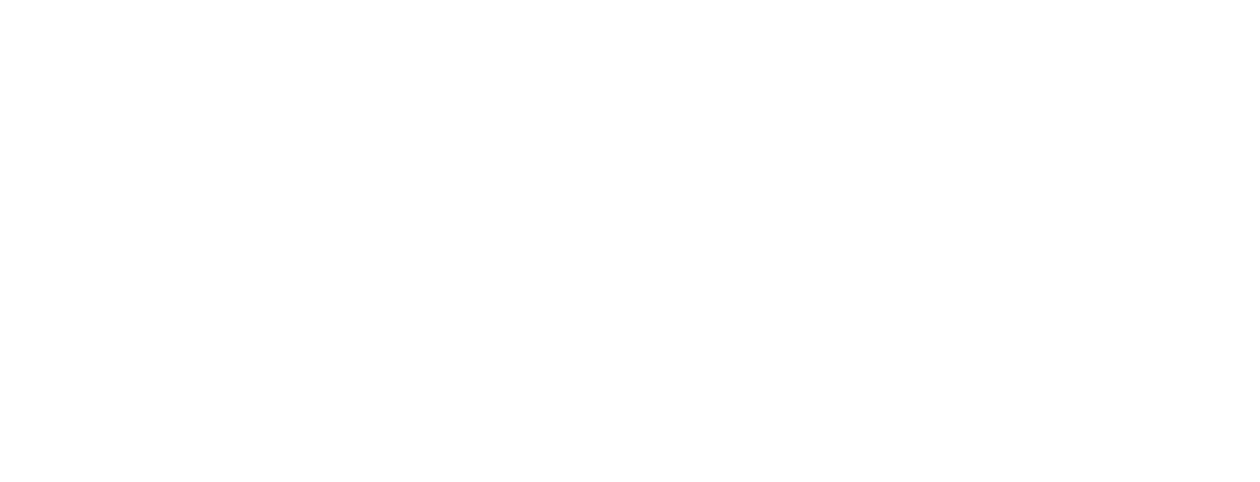

In [6]:
THUMB_SIZE = (400, 270)  # ~5% of the 8192x5464 original

def load_thumbnail(path: Path, size=THUMB_SIZE) -> Image.Image:
    """Open a JPEG at reduced size without fully decoding the 45 MP image."""
    with Image.open(path) as img:
        img.draft("RGB", size)
        img = img.convert("RGB")
        img.thumbnail(size)
        return img.copy()

def show_images(subset: pd.DataFrame, n=8, cols=4, seed=0):
    """Display n random images from `subset` as a grid of thumbnails."""
    sample = subset.sample(min(n, len(subset)), random_state=seed)
    rows = -(-len(sample) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
    axes = axes.ravel() if hasattr(axes, "ravel") else [axes]
    for ax in axes:
        ax.axis("off")
    for ax, (_, row) in zip(axes, sample.iterrows()):
        ax.imshow(load_thumbnail(row["path"]))
        ax.set_title(f"{row['sample']} | {row['type']} | {row['state']}", fontsize=9)
    plt.tight_layout()
    plt.show()

show_images(df, n=8)

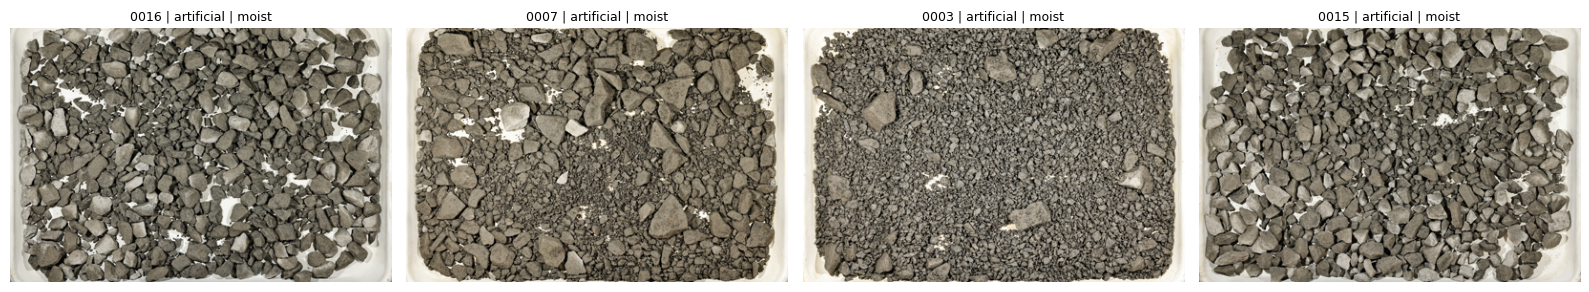

In [7]:
show_images(df[(df["type"] == "artificial") & (df["state"] != "dry")], n=4, seed=4)

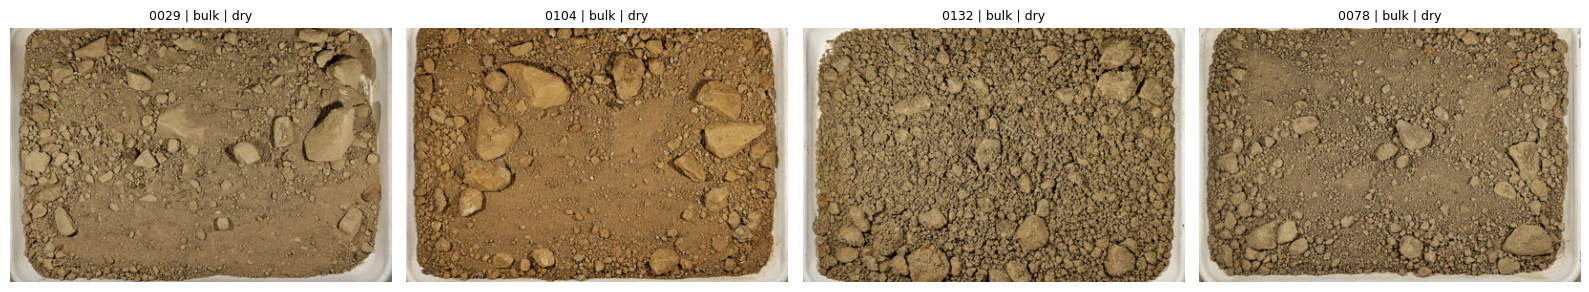

In [8]:
show_images(df[(df["type"] != "artificial") & (df["state"] == "dry")], n=4, seed=4)

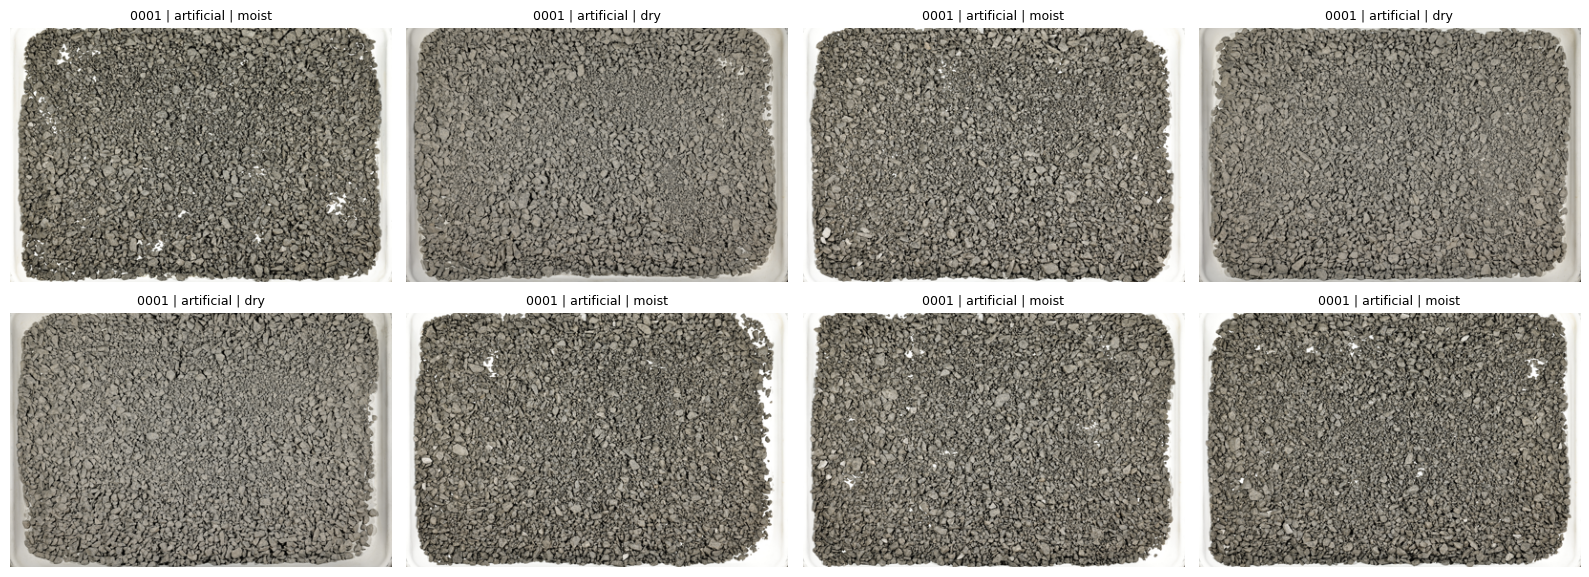

In [11]:
show_images(df[df["sample"] == "0001"], n=8, seed=4)